# 🏛️ Refactorización y Optimización del Modelo Dimensional — ACTHO 360 (Arquitectura Medallion con `pandas`)

Este notebook ejecuta y documenta por etapas la **refactorización integral del modelo dimensional de ACTHO 360** en una carpeta completamente independiente (`d:\analisis_exploratorio\modelo_refactorizado_actho360\`), **conservando intactos todos los archivos originales** en `d:\analisis_exploratorio\data\normalizados\`:

- **Etapa 1 (Fase 1)**: Diagnóstico exhaustivo del modelo actual con `pandas` (conteos, nulos, claves primarias, claves foráneas huérfanas, métricas acopladas en dimensiones y granularidad).
- **Etapa 2 (Fases 2, 3 y 4)**: Diseño del nuevo modelo dimensional, separación de responsabilidades, implementación de **SCD Type 2** (`dim_empresas_scd2`), homologación canónica de **`KAM-UNASSIGNED`** y preservación de respuestas de encuesta sin inventar puntuaciones NPS 0–10 desde escalas 1–5.
- **Etapa 3 (Fases 5, 6 y 7)**: Construcción de las capas **Bronze**, **Silver** y **Gold** (en CSV y Apache Parquet `.parquet`), tablas de agregación analítica (`agg_participacion_empresa`, `agg_satisfaccion_evento`, `agg_retencion_empresa`) y tablas de auditoría (`audit_registros_duplicados`, `audit_calidad_datos`, `audit_cargas`, `audit_reconciliacion_origen_destino`).
- **Etapa 4 (Fase 8)**: Ejecución de las pruebas automatizadas con **`pytest`** validando las 10 reglas de integridad, idempotencia y reconciliación.
- **Etapa 5**: Resumen de entregables generados.

---

## 🔍 Etapa 1 (Fase 1): Diagnóstico del Modelo Dimensional Actual con `pandas`

Inspeccionamos las 8 tablas de entrada sin modificarlas para detectar:
1. Cantidad de registros, columnas, porcentaje de nulos y claves primarias (`PK`).
2. Relaciones e integridad referencial (`FK` huérfanas como `'Sin asignar'` vs `'Sin asignar (cuenta ACTHO)'`).
3. Métricas agregadas almacenadas indebidamente dentro de las tablas de dimensiones (`dim_empresas`, `dim_personas`, `dim_eventos`, `dim_kams`).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ORIG_NORM_DIR = r"d:\analisis_exploratorio\data\normalizados"
ORIG_DUP_DIR = os.path.join(ORIG_NORM_DIR, "duplicados")
OUT_ROOT = r"d:\analisis_exploratorio\modelo_refactorizado_actho360"

try:
    from IPython.display import HTML, display
except ImportError:
    display = print
    HTML = str

if "mostrar_df" not in globals():
    def mostrar_df(df: pd.DataFrame, titulo: str = "", max_filas: int = 15) -> None:
        if titulo:
            display(HTML(f"<h4 style='color:#1e1b4b;margin:10px 0 4px 0;'>{titulo}</h4>"))
        display(df.head(max_filas))

tablas_entrada = {
    "dim_empresas.csv": ("id_empresa", os.path.join(ORIG_NORM_DIR, "dim_empresas.csv"), "1 fila por empresa única (mezcla atributos y 9 métricas)"),
    "dim_personas.csv": ("id_persona", os.path.join(ORIG_NORM_DIR, "dim_personas.csv"), "1 fila por persona única (mezcla atributos y 7 métricas)"),
    "dim_eventos.csv": ("id_evento", os.path.join(ORIG_NORM_DIR, "dim_eventos.csv"), "1 fila por evento 2026 (mezcla atributos y 4 métricas)"),
    "dim_kams.csv": ("kam_id", os.path.join(ORIG_NORM_DIR, "dim_kams.csv"), "1 fila por portafolio KAM (mezcla atributos y 8 métricas)"),
    "fact_asistencias.csv": ("id_asistencia", os.path.join(ORIG_NORM_DIR, "fact_asistencias.csv"), "1 fila por participación reportada en evento"),
    "fact_encuestas_satisfaccion.csv": ("id_respuesta", os.path.join(ORIG_NORM_DIR, "fact_encuestas_satisfaccion.csv"), "1 fila por respuesta de encuesta post-evento"),
    "fact_movimientos_crm.csv": (None, os.path.join(ORIG_NORM_DIR, "fact_movimientos_crm.csv"), "1 fila por movimiento comercial CRM (sin PK explícita)"),
    "registros_duplicados.csv": ("id_duplicado", os.path.join(ORIG_DUP_DIR, "registros_duplicados.csv"), "1 fila por registro duplicado detectado en origen"),
}

dfs_orig = {}
diag_rows = []
for nombre, (pk, ruta, gran) in tablas_entrada.items():
    df = pd.read_csv(ruta)
    dfs_orig[nombre] = df
    total_celdas = df.shape[0] * df.shape[1]
    nulos = int(df.isna().sum().sum())
    pct_nulos = round(nulos * 100 / total_celdas, 2)
    dup_pk = int(df[pk].duplicated().sum()) if pk and pk in df.columns else "Sin PK única"
    diag_rows.append({
        "Tabla Original": nombre,
        "Filas": len(df),
        "Columnas": df.shape[1],
        "Clave Primaria (PK)": pk or "FALTA PK (id_movimiento)",
        "Duplicados PK": dup_pk,
        "Celdas Nulas": nulos,
        "% Nulos": f"{pct_nulos:.2f}%",
        "Granularidad y Hallazgo Estructural": gran,
    })

df_diag_inicial = pd.DataFrame(diag_rows)
mostrar_df(df_diag_inicial, "1.1 Informe Inicial de Diagnóstico por Tabla (Modelo de Entrada)")

# Diagnóstico de Integridad Referencial antes de refactorizar
emp_ids = set(dfs_orig["dim_empresas.csv"]["id_empresa"].dropna())
per_ids = set(dfs_orig["dim_personas.csv"]["id_persona"].dropna())
ev_ids = set(dfs_orig["dim_eventos.csv"]["id_evento"].dropna())
kam_ids = set(dfs_orig["dim_kams.csv"]["kam_id"].dropna())

relaciones_eval = [
    ("dim_empresas.csv", "kam_id", "dim_kams.csv", kam_ids),
    ("dim_personas.csv", "id_empresa_principal", "dim_empresas.csv", emp_ids),
    ("fact_asistencias.csv", "id_empresa", "dim_empresas.csv", emp_ids),
    ("fact_asistencias.csv", "id_persona", "dim_personas.csv", per_ids),
    ("fact_asistencias.csv", "id_evento", "dim_eventos.csv", ev_ids),
    ("fact_asistencias.csv", "kam_id", "dim_kams.csv", kam_ids),
    ("fact_encuestas_satisfaccion.csv", "id_persona", "dim_personas.csv", per_ids),
    ("fact_encuestas_satisfaccion.csv", "id_empresa", "dim_empresas.csv", emp_ids),
    ("fact_movimientos_crm.csv", "id_empresa", "dim_empresas.csv", emp_ids),
    ("fact_movimientos_crm.csv", "kam_id", "dim_kams.csv", kam_ids),
    ("fact_movimientos_crm.csv", "id_persona_contacto", "dim_personas.csv", per_ids),
]

fk_diag_rows = []
for t_origen, col_fk, t_destino, cjto_pk in relaciones_eval:
    serie = dfs_orig[t_origen][col_fk]
    nulos_fk = int(serie.isna().sum())
    no_nulos = serie.dropna()
    huerfanos = [v for v in no_nulos if v not in cjto_pk]
    fk_diag_rows.append({
        "Tabla Origen": t_origen,
        "Columna FK": col_fk,
        "Dimensión Destino": t_destino,
        "Registros Nulos": nulos_fk,
        "Claves Huérfanas": len(huerfanos),
        "Valores Huérfanos Detectados": ", ".join(sorted(set(map(str, huerfanos)))) if huerfanos else "0 (100% íntegro)",
    })

df_fk_diag = pd.DataFrame(fk_diag_rows)
mostrar_df(df_fk_diag, "1.2 Diagnóstico de Integridad Referencial antes de la Refactorización")

---

## 🛠️ Etapas 2 y 3 (Fases 2 a 7): Refactorización de Dimensiones, Hechos, Agregaciones Gold y Auditoría

Ejecutamos el pipeline modular `refactorizar_modelo_actho360.py` que escribe todos los resultados en `d:\analisis_exploratorio\modelo_refactorizado_actho360\` (formatos `.csv` y `.parquet`), aplicando:
1. **`silver/dim_kams`**: Separa las 8 métricas agregadas y homologa `Sin asignar` y `Sin asignar (cuenta ACTHO)` al identificador canónico **`KAM-UNASSIGNED`**.
2. **`silver/dim_empresas` y `silver/dim_empresas_scd2`**: Separa las 9 métricas derivadas de participación/encuestas e implementa **Slowly Changing Dimension Tipo 2 (`dim_empresas_scd2`)** con las 1,872 versiones históricas y actuales de membresía.
3. **`silver/dim_personas`**: Separa las 7 métricas calculadas y conserva las 14 personas sin empresa con `estado_resolucion_empresa = 'SIN_EMPRESA_ASOCIADA'`.
4. **`silver/dim_eventos`**: Separa las 4 métricas de origen hacia `audit/audit_metricas_origen_eventos.csv`.
5. **`silver/fact_asistencias` (`3,401` filas)**: Homologa `kam_id` a `KAM-UNASSIGNED`, agrega `tipo_asistencia` y `modalidad_evento`, y clasifica las 15 asistencias sin `id_empresa` como `PENDIENTE_RESOLUCION_EMPRESA`.
6. **`silver/fact_encuestas_satisfaccion` (`725` filas)**: Conserva las respuestas anónimas clasificadas en `estado_resolucion_identidad`, agrega `id_evento` (`Int64` nulo) y **no inventa un NPS 0–10 a partir de la escala 1–5**, dejando `pregunta_recomendacion_nps_0_10 = NaN` listo para la futura encuesta de 90 días.
7. **`silver/fact_movimientos_crm` (`77` filas)**: Crea la clave primaria única **`id_movimiento`** (`MOV-0001..MOV-0077`), homologa `kam_id` y clasifica los nulos de fecha de expiración.

In [2]:
import sys
sys.path.insert(0, os.path.join(OUT_ROOT, "etl"))
from refactorizar_modelo_actho360 import ejecutar_pipeline_completo

resultado_etl = ejecutar_pipeline_completo()
SILVER_DIR = os.path.join(OUT_ROOT, "silver")
GOLD_DIR = os.path.join(OUT_ROOT, "gold")
AUDIT_DIR = os.path.join(OUT_ROOT, "audit")

mostrar_df(resultado_etl["reconciliacion"], "2.1 Reconciliación Exacta Origen (Bronze) vs Destino Refactorizado (Silver)")
mostrar_df(resultado_etl["calidad"], "2.2 Registro de Incidencias y Reglas Aplicadas en audit_calidad_datos.csv", max_filas=20)

---

## 🥈 Inspección de las Tablas Refactorizadas en Capa `Silver` (CSV y Apache Parquet)

Verificamos la estructura limpia de las dimensiones (`dim_kams`, `dim_empresas`, `dim_empresas_scd2`, `dim_personas`, `dim_eventos`) y de las tablas de hechos (`fact_asistencias`, `fact_encuestas_satisfaccion`, `fact_movimientos_crm`), comprobando que **0 claves foráneas quedan huérfanas**:

In [3]:
dim_kams_s = pd.read_parquet(os.path.join(SILVER_DIR, "dim_kams.parquet"))
dim_emp_s = pd.read_parquet(os.path.join(SILVER_DIR, "dim_empresas.parquet"))
dim_emp_scd2 = pd.read_parquet(os.path.join(SILVER_DIR, "dim_empresas_scd2.parquet"))
dim_per_s = pd.read_parquet(os.path.join(SILVER_DIR, "dim_personas.parquet"))
dim_ev_s = pd.read_parquet(os.path.join(SILVER_DIR, "dim_eventos.parquet"))
fact_asist_s = pd.read_parquet(os.path.join(SILVER_DIR, "fact_asistencias.parquet"))
fact_enc_s = pd.read_parquet(os.path.join(SILVER_DIR, "fact_encuestas_satisfaccion.parquet"))
fact_mov_s = pd.read_parquet(os.path.join(SILVER_DIR, "fact_movimientos_crm.parquet"))

mostrar_df(dim_kams_s, "3.1 silver/dim_kams.parquet — Dimensión KAM Descriptiva con KAM-UNASSIGNED Homologado")
mostrar_df(
    dim_emp_scd2[dim_emp_scd2["id_empresa"].isin(["EMP-0054", "EMP-0183", "EMP-0250", "EMP-0357", "EMP-0505"])],
    "3.2 silver/dim_empresas_scd2.parquet — Historial SCD Tipo 2 (Versiones Históricas vs Vigentes)",
)
mostrar_df(dim_per_s.head(8), "3.3 silver/dim_personas.parquet — Atributos Descriptivos sin Métricas Acopladas")
mostrar_df(fact_mov_s.head(8), "3.4 silver/fact_movimientos_crm.parquet — Con Clave Primaria id_movimiento y Clasificación de Expiración")

kam_id,kam_etiqueta_original,responsable_nombre,tiene_seguimiento_eventos,es_kam_asignado
KAM A,KAM A,Paula,True,True
KAM B,KAM B,Priscilla,True,True
KAM C,KAM C,Erika,True,True
KAM D,KAM D,Marcel,True,True
KAM E,KAM E,Mari,True,True
KAM F,KAM F,Yolanda,True,True
KAM G,KAM G,No especificado,False,True
KAM H,KAM H,No especificado,False,True
KAM I,KAM I,No especificado,False,True
KAM-UNASSIGNED,Sin asignar (cuenta ACTHO),Corporativo / Sin asignar,False,False


---

## 🥇 Inspección de la Capa `Gold` (`agg_participacion_empresa`, `agg_satisfaccion_evento`, `agg_retencion_empresa`) y `Audit`

Revisamos las tres tablas de agregación analítica en `gold/` y las tablas de trazabilidad en `audit/`, junto con gráficos `matplotlib` del estado de resolución de identidad, categorías de duplicados y el semáforo de retención:

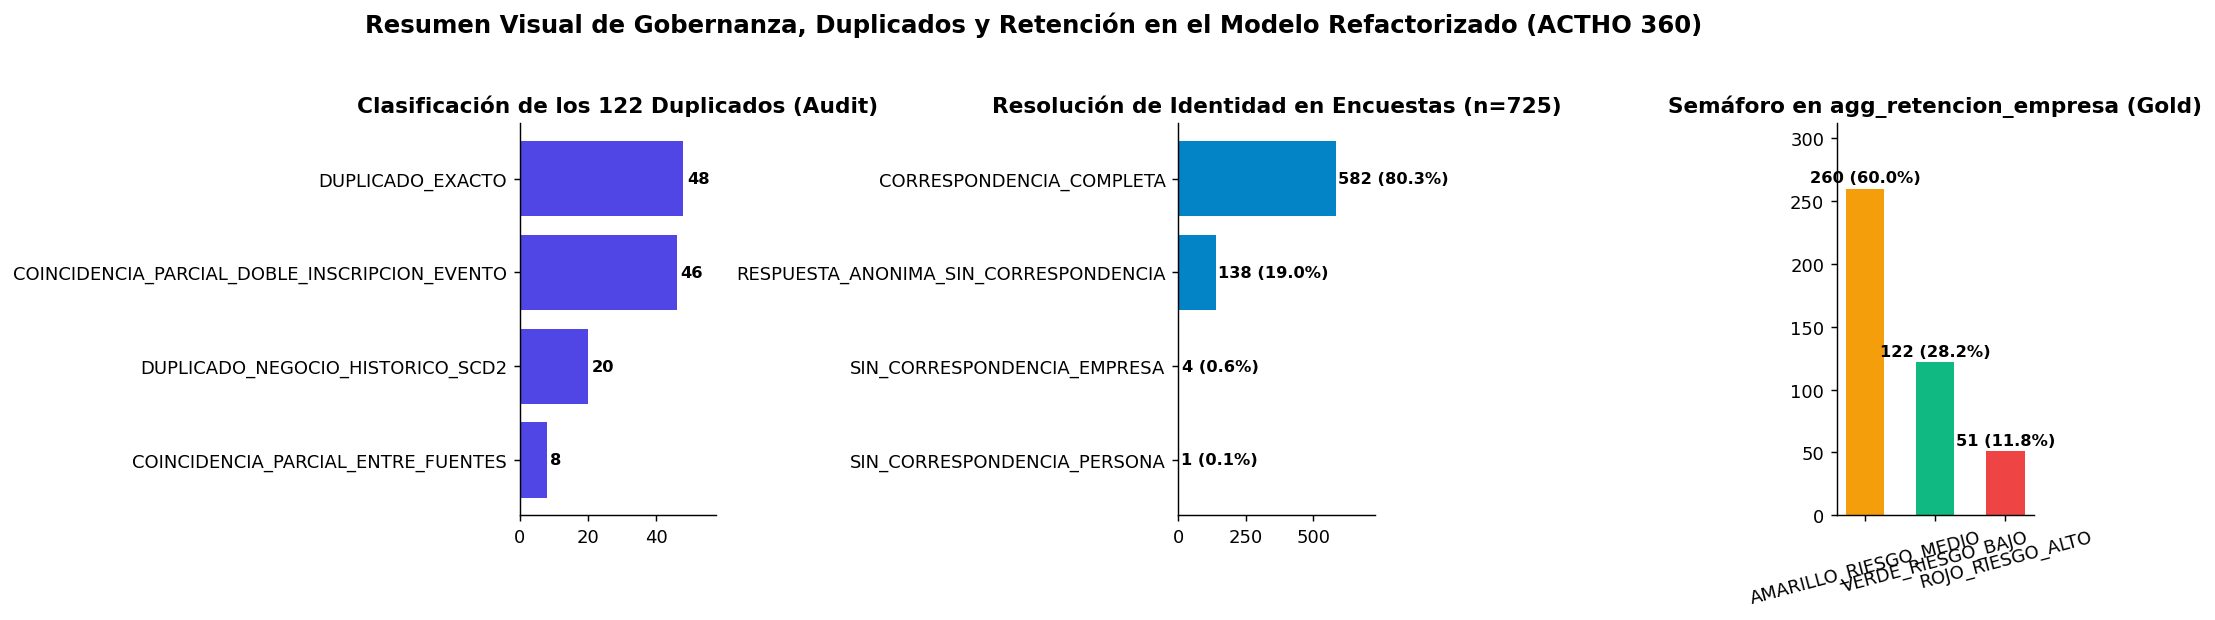

In [4]:
agg_part = pd.read_parquet(os.path.join(GOLD_DIR, "agg_participacion_empresa.parquet"))
agg_sat = pd.read_parquet(os.path.join(GOLD_DIR, "agg_satisfaccion_encuestas.parquet"))
agg_ret = pd.read_parquet(os.path.join(GOLD_DIR, "agg_retencion_empresa.parquet"))
audit_dup = pd.read_parquet(os.path.join(AUDIT_DIR, "audit_registros_duplicados.parquet"))
audit_ev = pd.read_parquet(os.path.join(AUDIT_DIR, "audit_metricas_origen_eventos.parquet"))
audit_hashes = pd.read_parquet(os.path.join(AUDIT_DIR, "audit_hashes_fuentes_bronze.parquet"))
audit_cargas = pd.read_parquet(os.path.join(AUDIT_DIR, "audit_cargas.parquet"))

mostrar_df(audit_hashes, "4.0 audit/audit_hashes_fuentes_bronze.parquet (Verificación SHA-256 e Inmutabilidad Bronze)")
mostrar_df(agg_part.sort_values("total_asistencias", ascending=False).head(10), "4.1 gold/agg_participacion_empresa.parquet (Trimestre Calendario, Ventana Móvil 90d y Recencia)")
mostrar_df(agg_sat, "4.2 gold/agg_satisfaccion_encuestas.parquet (Sin inferencia de eventos y satisfacción 1-5 separada de NPS 0-10)", max_filas=15)
mostrar_df(
    agg_ret[agg_ret["es_membresia_activa"] == True].sort_values("dias_para_expiracion").head(10),
    "4.3 gold/agg_retencion_empresa.parquet (Separación Vencidas vs Próximas 90d, Retiros vs Historial SCD2 y Semáforo Heurístico)",
)
mostrar_df(audit_dup.head(10), "4.4 audit/audit_registros_duplicados.parquet (122 Duplicados Clasificados y Trazados)")
mostrar_df(audit_cargas, "4.5 audit/audit_cargas.parquet (Bitácora de Ejecución ETL Separada de Datos Analíticos)")

# Gráficos de resumen con Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
fig.suptitle("Resumen Visual de Gobernanza, Duplicados y Retención en el Modelo Refactorizado (ACTHO 360)", fontsize=13.5, fontweight="bold", y=1.03)

# Panel 1: Categorías de duplicados en audit_registros_duplicados
dup_cat = audit_dup["categoria_duplicidad"].value_counts().sort_values(ascending=True)
axes[0].barh(dup_cat.index, dup_cat.values, color="#4f46e5")
for i, v in enumerate(dup_cat.values):
    axes[0].text(v + 1, i, str(v), va="center", fontweight="bold", fontsize=9)
axes[0].set_title("Clasificación de los 122 Duplicados (Audit)", fontweight="bold")
axes[0].set_xlim(0, max(dup_cat.values) * 1.2)

# Panel 2: Estado de resolución de identidad en fact_encuestas_satisfaccion
enc_id_st = fact_enc_s["estado_resolucion_identidad"].value_counts().sort_values(ascending=True)
axes[1].barh(enc_id_st.index, enc_id_st.values, color="#0284c7")
for i, v in enumerate(enc_id_st.values):
    axes[1].text(v + 8, i, f"{v} ({v*100/len(fact_enc_s):.1f}%)", va="center", fontweight="bold", fontsize=9)
axes[1].set_title("Resolución de Identidad en Encuestas (n=725)", fontweight="bold")
axes[1].set_xlim(0, max(enc_id_st.values) * 1.25)

# Panel 3: Semáforo de riesgo en agg_retencion_empresa (afiliados activos)
sem_cnt = agg_ret[agg_ret["es_membresia_activa"] == True]["semaforo_riesgo_renovacion"].value_counts()
colores_sem = {"VERDE_RIESGO_BAJO": "#10b981", "AMARILLO_RIESGO_MEDIO": "#f59e0b", "ROJO_RIESGO_ALTO": "#ef4444"}
axes[2].bar(sem_cnt.index, sem_cnt.values, color=[colores_sem.get(k, "#64748b") for k in sem_cnt.index], width=0.55)
for i, v in enumerate(sem_cnt.values):
    axes[2].text(i, v + 5, f"{v} ({v*100/sem_cnt.sum():.1f}%)", ha="center", fontweight="bold", fontsize=9)
axes[2].set_title("Semáforo en agg_retencion_empresa (Gold)", fontweight="bold")
axes[2].set_ylim(0, max(sem_cnt.values) * 1.2)
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

---

## ✅ Etapa 4 (Fase 8): Ejecución de Validaciones y Pruebas Automatizadas con `pytest`

Ejecutamos desde el notebook la suite `tests/test_modelo_dimensional.py` que verifica automáticamente los 10 criterios exigidos (unicidad de claves primarias, integridad referencial del 100%, ausencia de métricas acopladas en dimensiones, no invención de NPS 0–10, homologación de `KAM-UNASSIGNED`, conservación del 100% de los registros de origen, consistencia de agregaciones e idempotencia):

In [5]:
import pytest

ret_code = pytest.main([
    os.path.join(OUT_ROOT, "tests", "test_modelo_dimensional.py"),
    "-v",
    "--tb=short",
])
print(f"\nCódigo de salida de pytest: {ret_code} (0 = 100% pruebas superadas)")

============================= test session starts =============================
platform win32 -- Python 3.10.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\nicolas.puerta\AppData\Local\Programs\Python\Python310\python.exe
cachedir: .pytest_cache
rootdir: D:\analisis_exploratorio
plugins: anyio-4.6.0
collecting ... collected 10 items

modelo_refactorizado_actho360/tests/test_modelo_dimensional.py::test_01_claves_primarias_unicas_y_no_nulas PASSED [ 10%]
modelo_refactorizado_actho360/tests/test_modelo_dimensional.py::test_02_integridad_referencial_y_homologacion_kam PASSED [ 20%]
modelo_refactorizado_actho360/tests/test_modelo_dimensional.py::test_03_reconciliacion_bronze_silver_y_hashes_inmutables PASSED [ 30%]
modelo_refactorizado_actho360/tests/test_modelo_dimensional.py::test_04_conservacion_122_registros_duplicados PASSED [ 40%]
modelo_refactorizado_actho360/tests/test_modelo_dimensional.py::test_05_ausencia_nps_ficticio_y_separacion_satisfaccion_1_5 PASSED [ 50%]
modelo_refactorizado_